**Name:** Ibrahim Khaled Al-Khamis

**Id:** 2240004075

**Section:** 7MA01

**Course:**   ARTI 403 – Image Processing

---
# Lab 8:   Edge Detection

### Task 1: Apply Edge Detection Methods

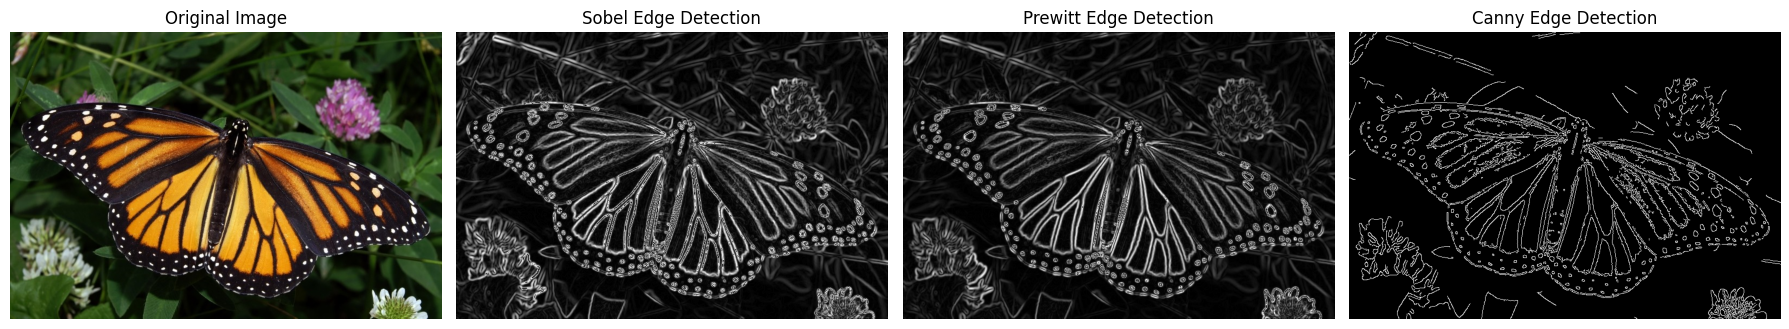

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imgFile = 'Butterfly.jpg'

img = cv2.imread(imgFile)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

# Sobel Edge Detector
sobelx = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)
sobel_combined = cv2.magnitude(sobelx, sobely)
sobel_final = np.uint8(np.absolute(sobel_combined))

# Prewitt Edge Detector
kernel_x = np.array([[-1, 0, 1],
                     [-1, 0, 1],
                     [-1, 0, 1]], dtype=np.float64)

kernel_y = np.array([[-1, -1, -1],
                     [0, 0, 0],
                     [1, 1, 1]], dtype=np.float64)

prewitt_x = cv2.filter2D(blurred, cv2.CV_64F, kernel_x)
prewitt_y = cv2.filter2D(blurred, cv2.CV_64F, kernel_y)
prewitt_combined = cv2.magnitude(prewitt_x, prewitt_y)
prewitt_final = np.uint8(np.absolute(prewitt_combined))

# Canny Edge Detector
canny_edges = cv2.Canny(gray, 100, 200)

# Display Results
plt.figure(figsize=(18, 5))

plt.subplot(1, 4, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(sobel_final, cmap='gray')
plt.title('Sobel Edge Detection')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(prewitt_final, cmap='gray')
plt.title('Prewitt Edge Detection')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(canny_edges, cmap='gray')
plt.title('Canny Edge Detection')
plt.axis('off')

plt.tight_layout()
plt.show()


### Task 2: Investigate the Effect of Canny Thresholds

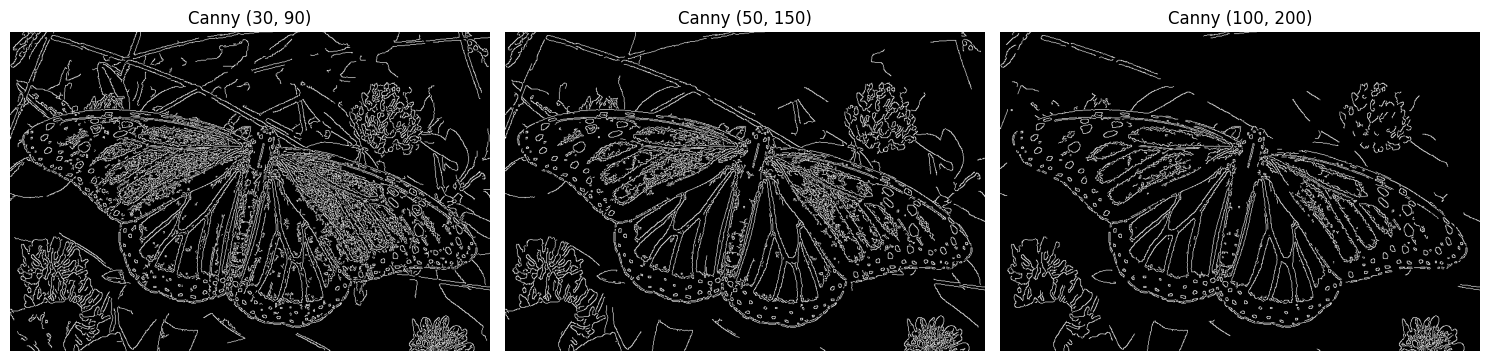

In [3]:

# Apply Canny with different thresholds
canny_30_90 = cv2.Canny(gray, 30, 90)
canny_50_150 = cv2.Canny(gray, 50, 150)
canny_100_200 = cv2.Canny(gray, 100, 200)

# Display Results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(canny_30_90, cmap='gray')
plt.title('Canny (30, 90)')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(canny_50_150, cmap='gray')
plt.title('Canny (50, 150)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(canny_100_200, cmap='gray')
plt.title('Canny (100, 200)')
plt.axis('off')

plt.tight_layout()
plt.show()



### Results and Discussion

- **Low = 30, High = 90:** More edges are detected, including small details and background noise.
- **Low = 50, High = 150:** Fewer edges are detected, but the main details of the butterfly are still visible.
- **Low = 100, High = 200:** Only stronger edges are detected, and some small details disappear.

**Conclusion:**

When the thresholds increase, the number of detected edges decreases. Lower thresholds detect more details but also more noise. Higher thresholds reduce noise but may miss weak edges. The middle thresholds provide a better balance between details and noise.


---